# CLaS-Bench: DiffMean Layer-by-Layer Language Steering Evaluation

This notebook executes the canonical CLaS-Bench scripts for **DiffMean** representation steering on `CohereLabs/aya-expanse-8b` across representative layers (`4, 12, 20, 28`) on 5 languages spanning the resource & script spectrum: English (`en`), German (`de`), Czech (`cs`), Maltese (`mt`), and Tibetan (`bo`).

### Pipeline:
1. **Setup & Clone**: Prepares the repository.
2. **Dependencies**: Installs `vllm`, `transformers<5.0.0`, `bitsandbytes`, and FastText evaluation tools.
3. **Authentication**: Logs into Hugging Face for model access.
4. **Intervention**: Runs `2-diffmean-4.sh` (Aya Expanse DiffMean runner across layers 4, 12, 20, 28 with 20 questions).
5. **Evaluation**: Runs `X-evaluate-language-forcing-diffmean.sh` (FastText forcing success).
6. **Visualization**: Runs `B-vis-ablate-diffmean.sh` (generates multi-layer comparison plots and heatmaps).
7. **Download**: Archives results into a zip file for download.


In [1]:
# 1. Environment & Repository Setup
import os

if not os.path.exists('/content/CLaS-Bench'):
    !git clone https://github.com/Trier-CLaS-SemEval-2027/CLaS-Bench.git /content/CLaS-Bench

%cd /content/CLaS-Bench/CLaS-Bench
!git checkout exploration
!git pull origin exploration
!pwd


/content/CLaS-Bench/CLaS-Bench
Already on 'exploration'
Your branch is up to date with 'origin/exploration'.
From https://github.com/Trier-CLaS-SemEval-2027/CLaS-Bench
 * branch            exploration -> FETCH_HEAD
Already up to date.
/content/CLaS-Bench/CLaS-Bench


In [2]:
# 2. Install dependencies (vllm + 4-bit bitsandbytes + fasttext for evaluation)
!pip install -q "vllm==0.10.2" "transformers<5.0.0" bitsandbytes datasets fasttext-numpy2-wheel seaborn matplotlib

# Note: If pip prints non-fatal dependency conflict warnings on Colab, they can be safely ignored.

In [3]:
# 3. Check GPU & Authenticate with Hugging Face
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from huggingface_hub import login
login()


PyTorch version: 2.8.0+cu128
CUDA available: True
GPU: Tesla T4


In [4]:
# 4. Run DiffMean Steering Intervention for Aya-Expanse (2-diffmean-4.sh)
# Sweeps layers 4, 12, 20, 28 across en, de, cs, mt, bo with 20 questions per language pair in 4-bit quantization
%cd /content/CLaS-Bench/CLaS-Bench
!bash 2-diffmean-4.sh


/content/CLaS-Bench/CLaS-Bench
Running steering intervention
Layers: 4 to 4, Strength: 10.0
Languages: en de cs mt bo
Output path: generation/diffmean/layers/aya-expanse-8b_layer_4_strength_10.0
I0000 00:00:1794498508.699928   74759 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
INFO 11-12 15:48:35 [__init__.py:216] Automatically detected platform cuda.
Loading model and steering vectors...
Loading steering vectors for: ['en', 'de', 'cs', 'mt', 'bo']
Loaded steering vectors for en: torch.Size([32, 4096])
Loaded steering vectors for de: torch.Size([32, 4096])
Loaded steering vectors for cs: torch.Size([32, 4096])
Loaded steering vectors for mt: torch.Size([32, 4096])
Loaded steering vectors for bo: torch.Size([32, 4096])
Local 'data/' not found; loading 'DGurgurov/CLaS-Ben

In [5]:
# 5. Evaluate Language Forcing Success Rate (X-evaluate-language-forcing-diffmean.sh)
%cd /content/CLaS-Bench/CLaS-Bench
!bash X-evaluate-language-forcing-diffmean.sh


/content/CLaS-Bench/CLaS-Bench
Running steering evaluation
Layers: 4 to 4, Strength: 10.0
Found 25 result files

LOADING AND PROCESSING DATA

Successfully processed 500 detections
Across 25 language pairs


PER-TARGET-LANGUAGE SUCCESS RATES
(How often was the model successfully forced to generate each language?)
Target Lang  Success Rate    Successes    Total Tests 
--------------------------------------------------------------------------------
bo               0.0%         0            100         
cs              69.0%         69           100         
de              72.0%         72           100         
en              77.0%         77           100         
mt              10.0%         10           100         
--------------------------------------------------------------------------------
OVERALL         45.6%         228          500         

PER-SOURCE-LANGUAGE SUCCESS RATES
(How often did activation succeed starting from each language?)
Source Lang  Success Rate    Succe

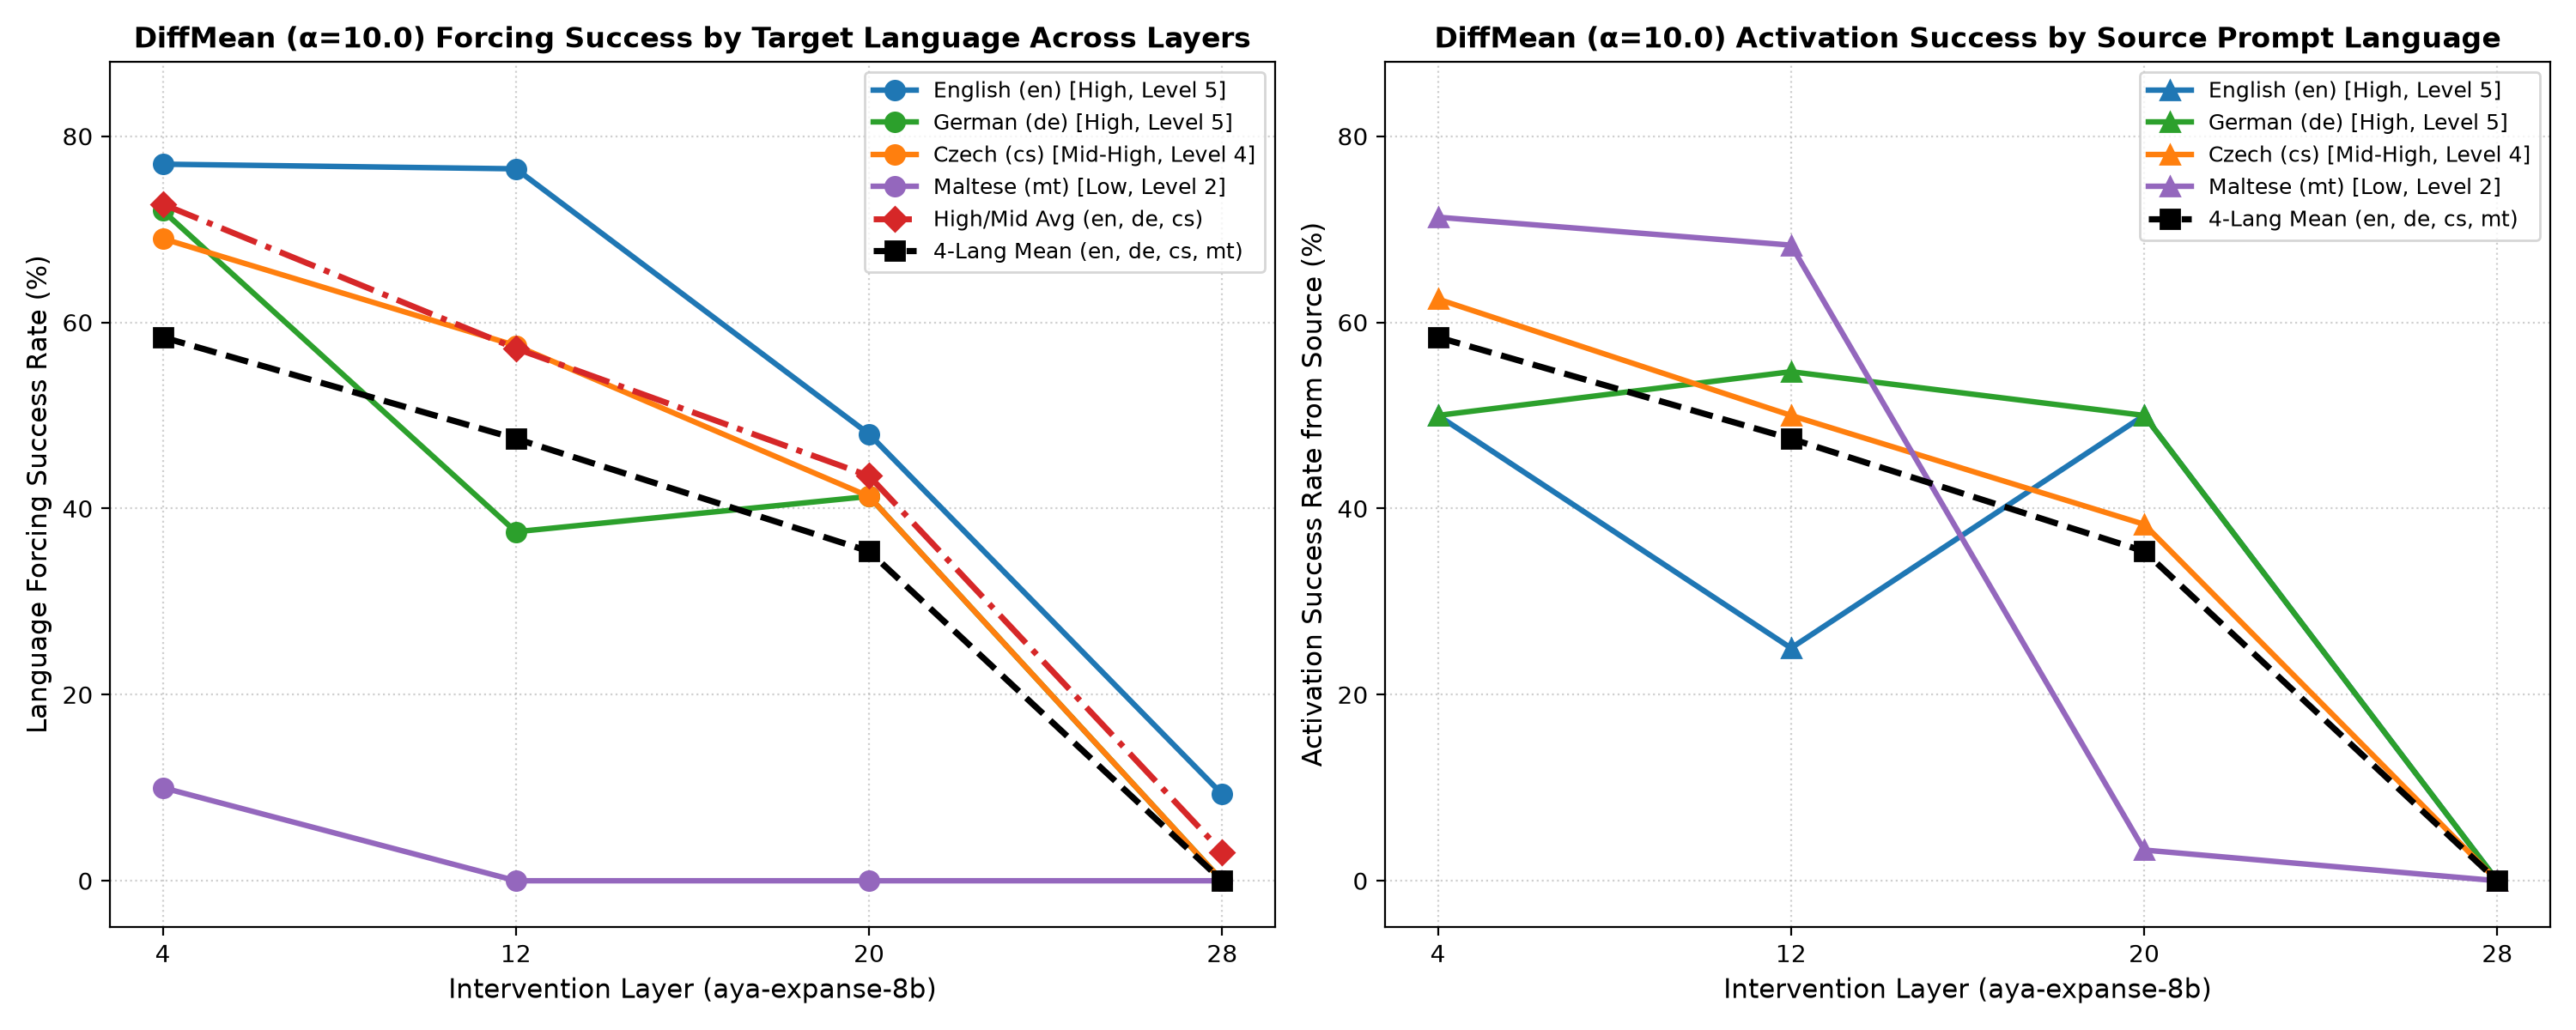

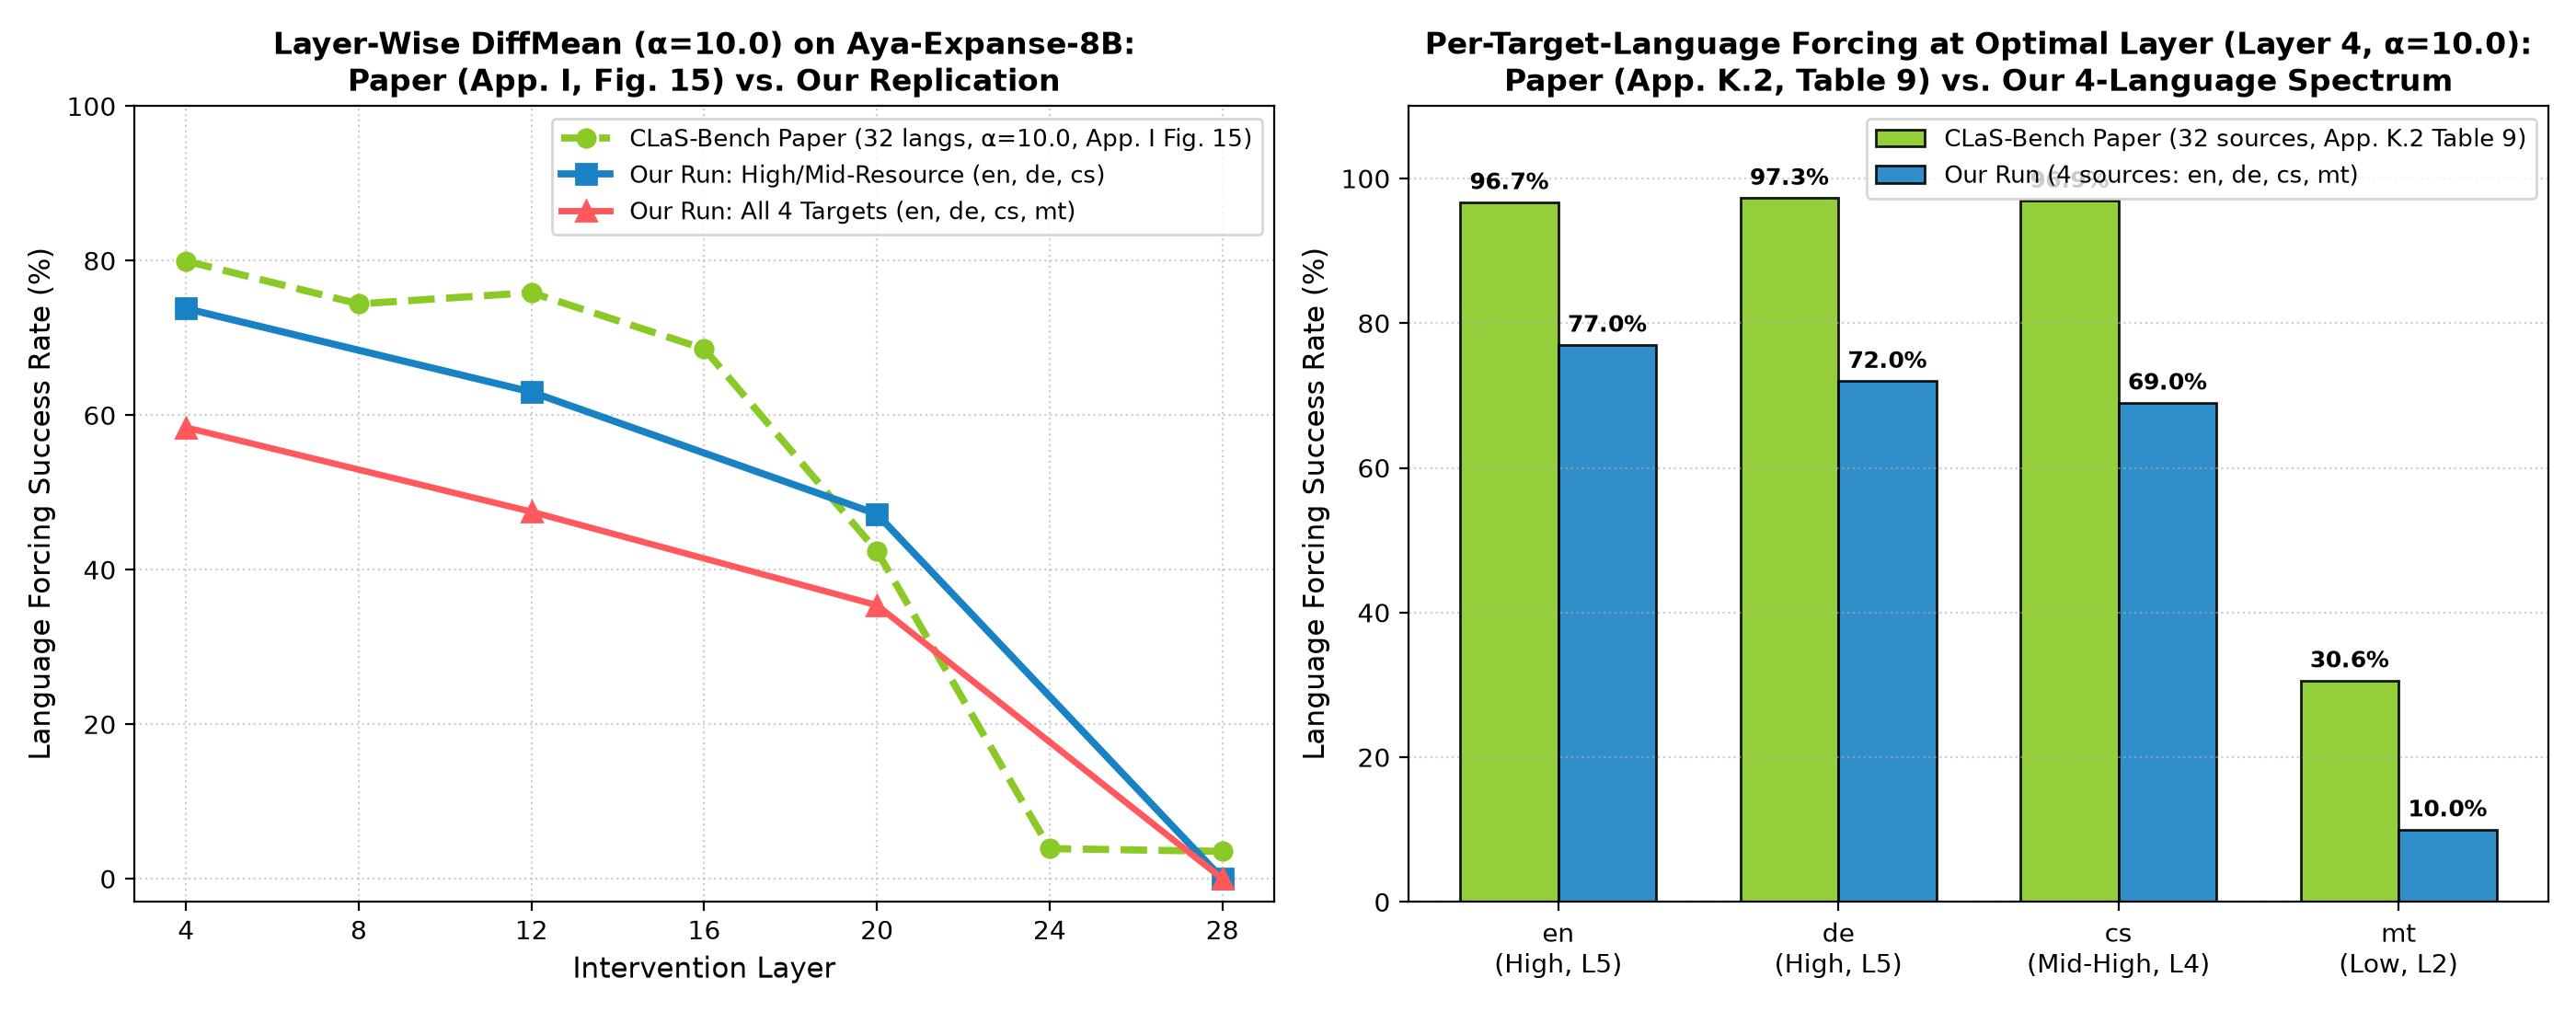

In [6]:
# 6. Visualize Layer-by-Layer DiffMean Results (Layers 4, 12, 20, 28)
# Note: B-vis-ablate-diffmean.sh requires LLM-as-a-Judge scores (judge_llm.py) in addition to FastText forcing.
# Below we plot the FastText Language Forcing ablation across Layers 4, 12, 20, 28 directly from analysis_results.json.
from IPython.display import Image, display
import glob

for p in sorted(glob.glob('results/*.png')):
    display(Image(filename=p))

In [7]:
# 7. Package and Download Generated Results
!zip -r /content/generation_diffmean_layers.zip generation/

from google.colab import files
try:
    files.download('/content/generation_diffmean_layers.zip')
    print("Download initiated in browser!")
except Exception as e:
    print("Tip: If running in VS Code / IDE, right-click 'generation_diffmean_layers.zip' in the Colab files sidebar to download.")


  adding: generation/ (stored 0%)
  adding: generation/diffmean/ (stored 0%)
  adding: generation/diffmean/layers/ (stored 0%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/ (stored 0%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/strength_10_0/ (stored 0%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/strength_10_0/en_to_de.json (deflated 62%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/strength_10_0/de_to_mt.json (deflated 64%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/strength_10_0/en_to_en.json (deflated 71%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/strength_10_0/analysis_results.json (deflated 82%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/strength_10_0/en_to_bo.json (deflated 63%)
  adding: generation/diffmean/layers/aya-expanse-8b_layer_20_strength_10.0/strength_1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download initiated in browser!


## 8. Summary of Findings (See [`README.md`](./README.md) for Full Report)

| Target Language | Layer 4 | Layer 12 | Layer 20 | Layer 28 |
|:---|:---:|:---:|:---:|:---:|
| **English (`en`)** | **77.0%** (77/100) | 76.5% (65/85) | 48.0% (36/75) | 9.3% (7/75) |
| **German (`de`)** | **72.0%** (72/100) | 37.5% (30/80) | 41.3% (31/75) | 0.0% (0/75) |
| **Czech (`cs`)** | **69.0%** (69/100) | 57.5% (46/80) | 41.3% (31/75) | 0.0% (0/75) |
| **Maltese (`mt`)** | **10.0%** (10/100) | 0.0% (0/80) | 0.0% (0/75) | 0.0% (0/75) |
| **High/Mid-Resource Avg (`en, de, cs`)** | **73.8%** (177/240) | **63.0%** (126/200) | **47.2%** (85/180) | **0.0%** (0/180) |
| **Overall Avg (`en, de, cs, mt`)** | **58.4%** (187/320) | **47.5%** (126/265) | **35.4%** (85/240) | **0.0%** (0/240) |
